# P1: Kryptonite-20 MLP pilot

Training seed 42; shared split seed 67. This notebook reproduces diagnostic figures from saved epoch logs. It does not train or score on the local test or hidden sets. Validation was used for checkpoint selection; these are exploratory results, not final held-out evidence.

From the repository root, generate the input artifacts with:

```bash
.venv/bin/python -m member_c.train --config member_c/configs/pilot_20.json --run-id pilot_20_seed42
```

Run directories are immutable: if reproducing training, choose a new run ID and update `run` below. The original source snapshot and its hashes are stored with the run. The 128-sample fitting diagnostic uses resubstitution and must not be interpreted as validation/generalization performance.

**Display:** Run all cells to plot directly below the code with `plt.show()`. No PDF or image files are exported. Matplotlib renders mathematical labels without external LaTeX.


In [1]:
from pathlib import Path
import csv
import json
import sys
import numpy as np
import matplotlib.pyplot as plt

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'common.py').is_file())
assert Path(sys.prefix).resolve() == (root / '.venv').resolve(), 'Use the project virtual environment kernel'
run = root / 'member_c/results/pilot_20_seed42'
summary = json.loads((run / 'summary.json').read_text())
with (run / 'history.csv').open() as f:
    rows = list(csv.DictReader(f))
history = {key: np.array([float(row[key]) for row in rows]) for key in rows[0]}
assert not summary['test_evaluated']
assert summary['epochs_run'] == len(rows)
print(f"Python: {sys.version.split()[0]}; device: CPU")
print(f"Best epoch: {summary['best_epoch']}; epochs run: {summary['epochs_run']}")
print(f"Training accuracy at best checkpoint: {summary['best_training']['accuracy']:.2%}")
print(f"Validation accuracy at best checkpoint: {summary['validation']['accuracy']:.2%}")
print(f"Trainable parameters: {summary['parameter_count']:,}")


Python: 3.12.4; device: CPU
Best epoch: 73; epochs run: 93
Training accuracy at best checkpoint: 99.20%
Validation accuracy at best checkpoint: 89.58%
Trainable parameters: 19,329


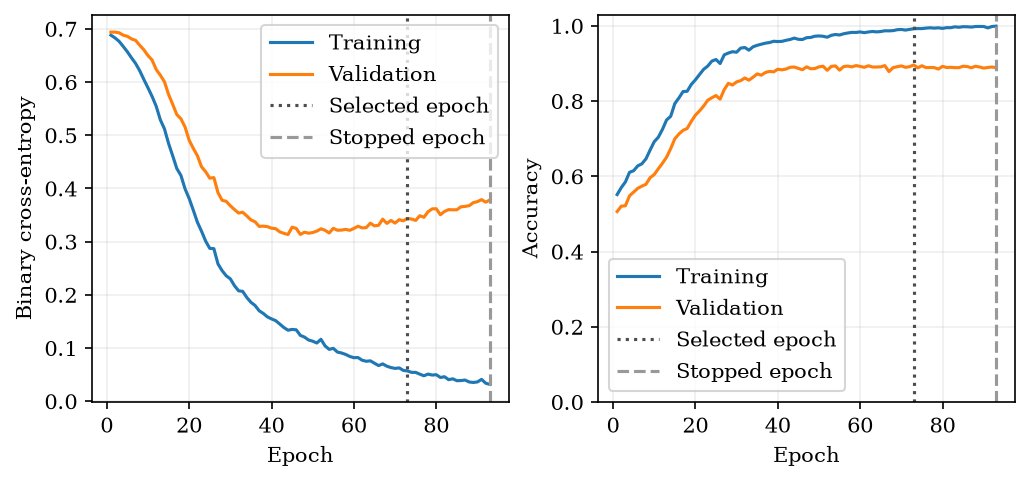

In [2]:
# Plot directly in the notebook; no file export or external LaTeX required.
plt.rcParams.update({
    'text.usetex': False, 'font.family': 'serif', 'font.serif': ['DejaVu Serif'],
    'font.size': 10.1, 'axes.labelsize': 10.1, 'xtick.labelsize': 10.1,
    'ytick.labelsize': 10.1, 'legend.fontsize': 10.1, 'figure.titlesize': 10.1,
    'axes.unicode_minus': True, 'figure.dpi': 150,
})
fig, axes = plt.subplots(1, 2, figsize=(6.75, 3.1), constrained_layout=True)
for ax, metric, label in zip(axes, ['loss', 'accuracy'], ['Binary cross-entropy', 'Accuracy']):
    ax.plot(history['epoch'], history[f'train_{metric}'], label='Training')
    ax.plot(history['epoch'], history[f'validation_{metric}'], label='Validation')
    ax.axvline(summary['best_epoch'], color='0.3', linestyle=':', label='Selected epoch')
    ax.axvline(summary['epochs_run'], color='0.6', linestyle='--', label='Stopped epoch')
    ax.set(xlabel='Epoch', ylabel=label)
    ax.grid(alpha=0.2)
    ax.legend()
axes[1].set_ylim(0, 1.03)
plt.show()


**Figure.** Training and validation curves for the two-hidden-layer MLP (128 units per layer) on Kryptonite-20. Loss and accuracy are evaluated after each epoch on the complete respective split, using that epoch's weights. The dashed line marks early stopping; the dotted line marks the checkpoint chosen by validation accuracy, with validation loss breaking ties. The optimization loss during minibatch updates is recorded separately in the CSV.

The training/validation gap is consistent with overfitting; this single seed and selected validation result do not establish the best architecture or a causal diagnosis. Later controlled comparisons and final held-out evaluation are separate stages.
